# Aprendizaje no supervisado — Segmentos de canciones (K-Means)
### Evaluación Parcial N°2 — MLY1101 Machine Learning

**Objetivo de negocio:** la distribuidora no tiene un solo tipo de canción en su catálogo. Si se descubren **grupos de canciones con un sonido parecido**, se puede entender qué segmentos existen, qué géneros los componen y qué tan populares son, para **diseñar estrategias de promoción distintas por segmento** en vez de una sola para todo el catálogo.

**Técnica elegida: K-Means** sobre las audio features.
- No hay una etiqueta que predecir: se busca estructura en los datos (aprendizaje no supervisado).
- Es simple, escala bien a ≈ 90.000 canciones y sus grupos se interpretan fácilmente mirando el promedio de cada variable por cluster.
- **Idea clave:** el clustering usa **solo el sonido** de la canción. El género y `popularity` **no** entran al algoritmo; se usan después para interpretar los grupos. Así se puede comprobar si los grupos "de sonido" coinciden con géneros reales y con la popularidad.

## 8. Clustering

### 8.1 Carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_style('whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('../data/processed/spotify_tracks_clean.csv')
genre_cols = [c for c in df.columns if c.startswith('genre_')]
print(df.shape)

(89740, 133)


### 8.2 Selección y estandarización de variables

K-Means usa distancias, por lo que las variables deben estar en la misma escala (por ejemplo `tempo` va de 0 a 240 y `energy` de 0 a 1). Se **estandarizan** (media 0, desviación 1) para que ninguna domine.

In [2]:
# Variables continuas del "sonido" de la canción. Se excluyen key, mode y time_signature
# (son categóricas) y duration_ms; el género y popularity NO entran al clustering:
# se usan después para interpretar los grupos.
audio_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                  'instrumentalness', 'liveness', 'valence', 'tempo']

scaler = StandardScaler()
X = scaler.fit_transform(df[audio_features])
print('Variables usadas:', len(audio_features), '| canciones:', X.shape[0])

Variables usadas: 9 | canciones: 89740


### 8.3 Elección del número de clusters (k)

Se prueban k de 2 a 10 con dos criterios:
- **Método del codo:** la inercia (distancia interna de los grupos) siempre baja al aumentar k; se busca dónde deja de bajar rápido.
- **Coeficiente de silueta:** mide qué tan bien separado está cada punto de otros grupos (de -1 a 1; más alto es mejor).

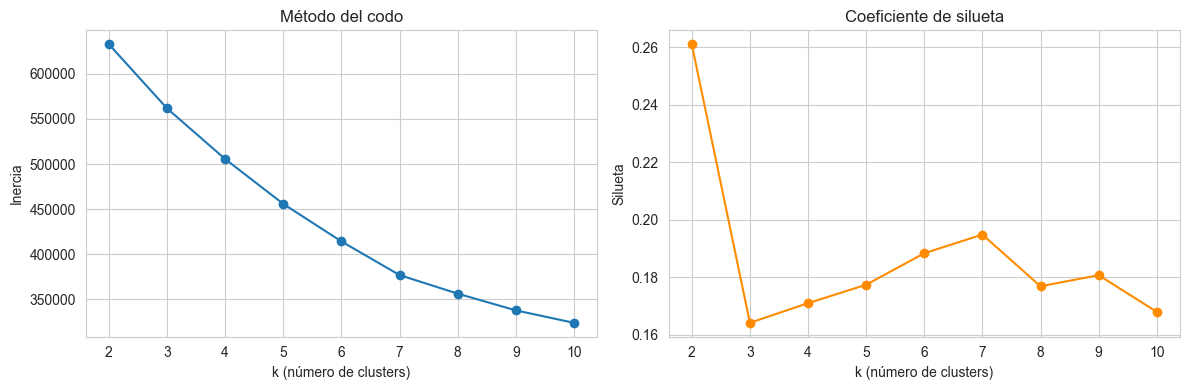

 k  inercia  silueta
 2 632735.0    0.261
 3 561696.0    0.164
 4 505598.0    0.171
 5 455891.0    0.177
 6 414346.0    0.188
 7 377050.0    0.195
 8 356486.0    0.177
 9 337944.0    0.181
10 324165.0    0.168


In [3]:
rng = np.random.RandomState(RANDOM_STATE)
muestra = rng.choice(len(X), 10000, replace=False)   # silhouette sobre muestra (es costoso en 90.000 filas)

ks = range(2, 11)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X[muestra], km.labels_[muestra]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inercia, marker='o')
axes[0].set_title('Método del codo'); axes[0].set_xlabel('k (número de clusters)'); axes[0].set_ylabel('Inercia')
axes[1].plot(list(ks), silueta, marker='o', color='darkorange')
axes[1].set_title('Coeficiente de silueta'); axes[1].set_xlabel('k (número de clusters)'); axes[1].set_ylabel('Silueta')
plt.tight_layout()
plt.savefig('../images/clustering_codo_silueta.png', dpi=100)
plt.show()

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercia), 'silueta': np.round(silueta, 3)}).to_string(index=False))

**Decisión: k = 6.**
- El codo **no marca un quiebre claro** (los datos de audio son un continuo, no grupos perfectamente separados).
- La silueta es máxima con k = 2 (0,26), pero eso solo separa "canciones intensas" de "canciones suaves": poco útil para el negocio. Desde k = 3 la silueta es baja (≈ 0,16-0,20) y su valor más alto está en **k = 7 (0,195)**; k = 6 queda apenas por debajo (0,188), igual que k = 5 y k = 8 (0,177).
- **k = 7 tiene una silueta apenas mayor que k = 6 (diferencia de 0,007); se prefirió k = 6 por interpretabilidad y simplicidad**: un segmento menos que explicar y grupos que coinciden con familias de géneros reales (ver 8.5). La comparación detallada entre ambos está en 8.8.5: k = 7 también es interpretable y separa un segmento de techno, por lo que es una alternativa válida.
- Los grupos de k = 6 son interpretables; el más pequeño (cluster 4, 1,2% de las canciones) corresponde a contenido hablado, claramente distinto del resto.
- Se reconoce que una silueta de ≈ 0,19 indica grupos **con solapamiento**: los segmentos son tendencias, no categorías cerradas (ver 8.8).

### 8.4 Ajuste del modelo final (K-Means con k = 6)

In [4]:
K = 6
df = df.copy()   # desfragmenta el DataFrame (tiene 114 columnas multi-hot) antes de agregar 'cluster'
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
df['cluster'] = kmeans.labels_
print('Silueta con k =', K, ':', round(silhouette_score(X[muestra], kmeans.labels_[muestra]), 3))
df['cluster'].value_counts().sort_index()

Silueta con k = 6 : 0.188


cluster
0    24302
1     6639
2    19471
3    31186
4     1052
5     7090
Name: count, dtype: int64

### 8.5 Interpretación de los clusters

El mapa de calor muestra, para cada cluster, cuántas desviaciones estándar está por encima (rojo) o por debajo (azul) del promedio general en cada variable.

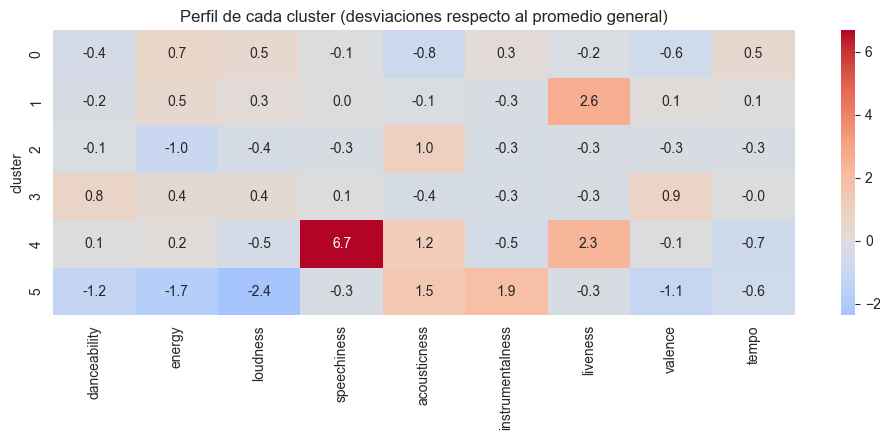

,canciones,popularity_media,pct_top,pct_explicit
cluster,,,,
0,24302,33.3,2.6,9.1
1,6639,34.8,1.4,6.2
2,19471,33.7,2.7,4.0
3,31186,33.8,4.7,11.9
4,1052,24.6,0.5,56.2
5,7090,28.6,0.4,0.3


In [5]:
perfil = df.groupby('cluster')[audio_features].mean()
z = (perfil - df[audio_features].mean()) / df[audio_features].std()   # cuántas desviaciones sobre/bajo el promedio

plt.figure(figsize=(10, 4.5))
sns.heatmap(z, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Perfil de cada cluster (desviaciones respecto al promedio general)')
plt.tight_layout()
plt.savefig('../images/clustering_perfil.png', dpi=100)
plt.show()

resumen = df.groupby('cluster').agg(canciones=('track_id', 'size'),
                                    popularity_media=('popularity', 'mean'),
                                    pct_top=('popularity', lambda s: (s > 70).mean() * 100),
                                    pct_explicit=('explicit', lambda s: s.mean() * 100)).round(1)
resumen

In [6]:
# Géneros sobrerrepresentados en cada cluster (lift = proporción en el cluster / proporción en todo el dataset)
base = df[genre_cols].mean()
for c in range(K):
    prop = df.loc[df['cluster'] == c, genre_cols].mean()
    lift = (prop / base)[prop > 0.02].sort_values(ascending=False).head(4)
    print(f'Cluster {c}:', ', '.join(f"{g.replace('genre_', '')} (x{v:.1f})" for g, v in lift.items()))

Cluster 0: death-metal (x3.4), grindcore (x3.3), black-metal (x3.3), metalcore (x3.2)
Cluster 1: pagode (x6.9), sertanejo (x6.0), samba (x5.7), mpb (x3.7)
Cluster 2: tango (x3.7), honky-tonk (x3.6), romance (x3.5), jazz (x3.5)
Cluster 3: reggaeton (x2.6), latino (x2.6), reggae (x2.5), dancehall (x2.5)
Cluster 4: comedy (x68.8), show-tunes (x2.8)
Cluster 5: new-age (x10.0), sleep (x9.9), classical (x9.3), ambient (x8.7)


**Segmentos encontrados** (los números de cluster pueden cambiar si se usa otra versión de scikit-learn; lo que se mantiene es el perfil):

| Cluster | Perfil de audio | Géneros característicos | Canciones | Popularity media | % top (>70) |
|---|---|---|---|---|---|
| 0 | **Intensas y agresivas**: energía y tempo altos, valence baja, poco acústicas | death-metal, grindcore, black-metal, metalcore | 24.302 | 33,3 | 2,6% |
| 1 | **En vivo**: `liveness` muy alta (+2,6 desv.) | pagode, sertanejo, samba, mpb | 6.639 | 34,8 | 1,4% |
| 2 | **Acústicas y suaves**: acousticness alta, energía baja | tango, honky-tonk, romance, jazz | 19.471 | 33,7 | 2,7% |
| 3 | **Bailables y alegres**: danceability y valence altas | reggaeton, latino, reggae, dancehall | 31.186 | 33,8 | **4,7%** |
| 4 | **Habladas**: `speechiness` extrema (+6,7 desv.), 56% explícitas | comedy (76% del cluster) | 1.052 | 24,6 | 0,5% |
| 5 | **Ambientales e instrumentales**: muy baja energía y loudness, alta instrumentalness | new-age, sleep, ambient, classical | 7.090 | 28,6 | 0,4% |

**Hallazgos:**
1. K-Means, sin conocer el género, **redescubrió agrupaciones de géneros coherentes** (por ejemplo, metal junto con metal, música para dormir junto con ambient). Eso valida que los segmentos tienen sentido musical.
2. El cluster 4 (comedy) es muy pequeño y muy distinto: es más bien contenido hablado que música.

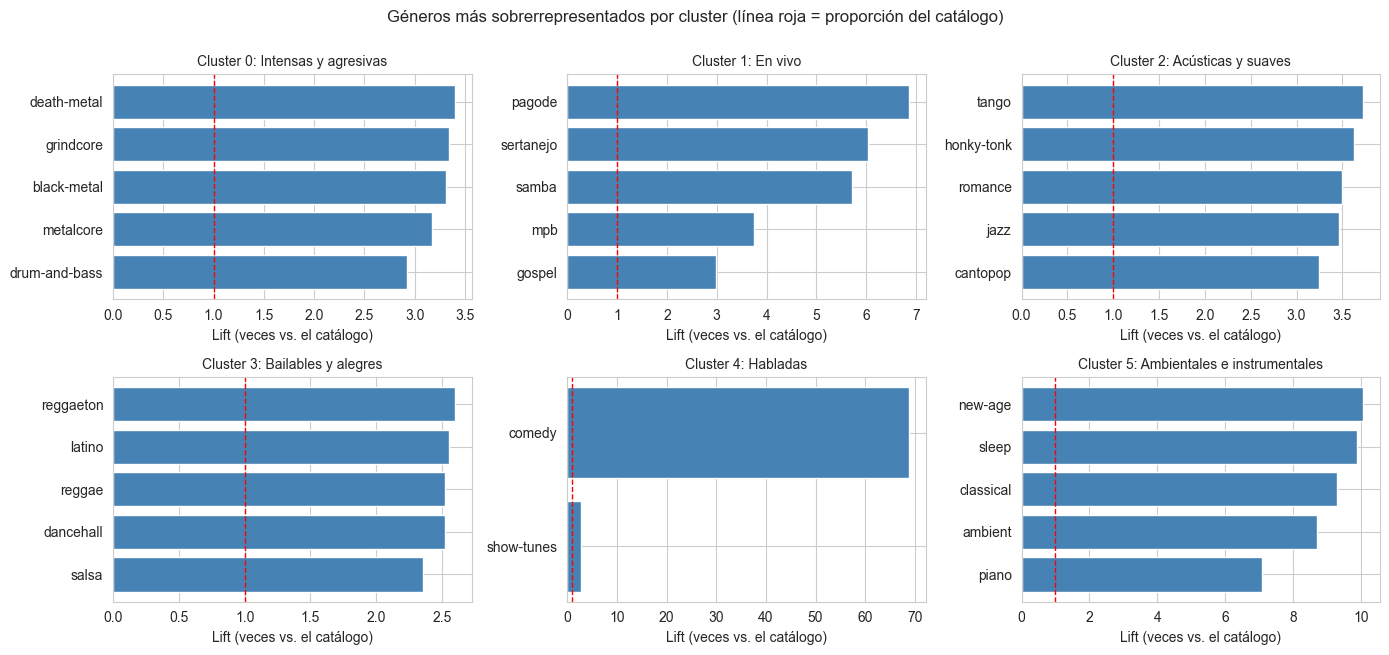

In [7]:
# Gráfico: géneros más sobrerrepresentados en cada cluster (lift)
nombres = {0: 'Intensas y agresivas', 1: 'En vivo', 2: 'Acústicas y suaves',
           3: 'Bailables y alegres', 4: 'Habladas', 5: 'Ambientales e instrumentales'}

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for c, ax in zip(range(K), axes.ravel()):
    prop = df.loc[df['cluster'] == c, genre_cols].mean()
    lift = (prop / base)[prop > 0.02].sort_values(ascending=False).head(5)[::-1]
    ax.barh([g.replace('genre_', '') for g in lift.index], lift.values, color='steelblue')
    ax.axvline(1, color='red', linestyle='--', linewidth=1)
    ax.set_title(f'Cluster {c}: {nombres[c]}', fontsize=10)
    ax.set_xlabel('Lift (veces vs. el catálogo)')
plt.suptitle('Géneros más sobrerrepresentados por cluster (línea roja = proporción del catálogo)', y=1.00)
plt.tight_layout()
plt.savefig('../images/clustering_generos_lift.png', dpi=100, bbox_inches='tight')
plt.show()

**Interpretación:** el *lift* indica cuántas veces más frecuente es un género dentro del cluster que en todo el catálogo (1 = igual; línea roja).
- Los clusters 4 y 5 son los más "puros": `comedy` es ×68,8 en el cluster 4, y `new-age`, `sleep`, `classical` y `ambient` están entre ×8,7 y ×10 en el cluster 5.
- En los clusters 0-3 los valores van de ×2,4 a ×6,9: cada segmento está **enriquecido** en ciertas familias de géneros, pero no las contiene en exclusiva (por ejemplo, el cluster 3 tiene reggaeton y latino ×2,6, pero la mayoría de sus canciones son de otros géneros).
- Por lo tanto, los segmentos de sonido se parecen a los géneros, pero **no los reemplazan**: son tendencias, no una clasificación por género.

### 8.6 Relación de los clusters con la popularidad

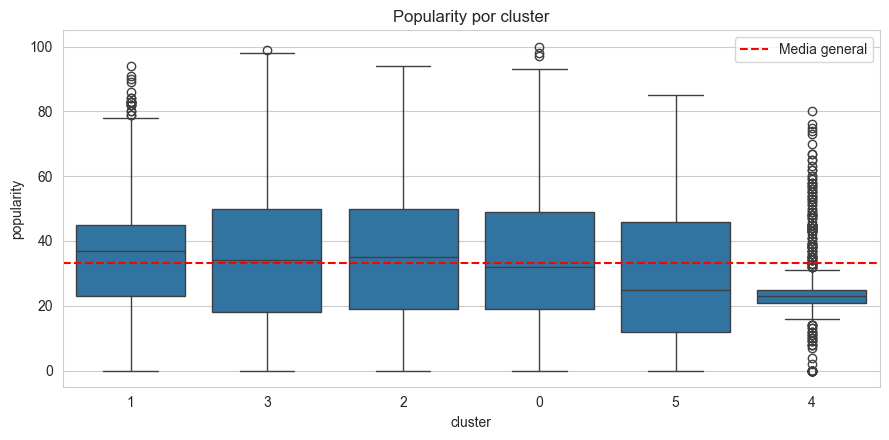

El cluster explica 0.7% de la variabilidad de popularity (eta²)


In [8]:
orden = df.groupby('cluster')['popularity'].mean().sort_values(ascending=False).index

plt.figure(figsize=(9, 4.5))
sns.boxplot(x='cluster', y='popularity', data=df, order=orden)
plt.axhline(df['popularity'].mean(), color='red', linestyle='--', label='Media general')
plt.title('Popularity por cluster')
plt.legend()
plt.tight_layout()
plt.savefig('../images/clustering_popularity.png', dpi=100)
plt.show()

# ¿Cuánta variabilidad de popularity explica el cluster? (eta cuadrado)
ss_entre = sum(len(g) * (g['popularity'].mean() - df['popularity'].mean()) ** 2 for _, g in df.groupby('cluster'))
ss_total = ((df['popularity'] - df['popularity'].mean()) ** 2).sum()
print(f'El cluster explica {ss_entre / ss_total:.1%} de la variabilidad de popularity (eta²)')

**Interpretación:**
- La popularidad promedio es parecida en los clusters 0-3 (≈ 33-35). Solo los clusters 4 (habladas) y 5 (ambientales) son claramente menos populares (≈ 25 y 29).
- El cluster **explica solo ≈ 0,7% de la variabilidad de `popularity`**: el sonido por sí solo casi no determina qué tan popular es una canción. Esto es **coherente con el EDA y con el modelo supervisado** (R² de 0,45 aun usando género), y refuerza que la popularidad depende de factores externos (artista, promoción, fecha).
- Donde sí hay diferencia es en las **canciones top**: el cluster 3 (bailables y alegres) tiene **4,7%** de canciones con popularity > 70, frente a 0,4-0,5% en los clusters 4 y 5. Es decir, el sonido bailable/alegre se asocia a una mayor probabilidad de éxito, aunque no lo garantiza.

### 8.7 Visualización de los clusters en 2D (PCA)

Para poder dibujar 9 variables en un plano se usa PCA (reducción de dimensionalidad). Es solo para visualizar; el clustering se hizo con las 9 variables.

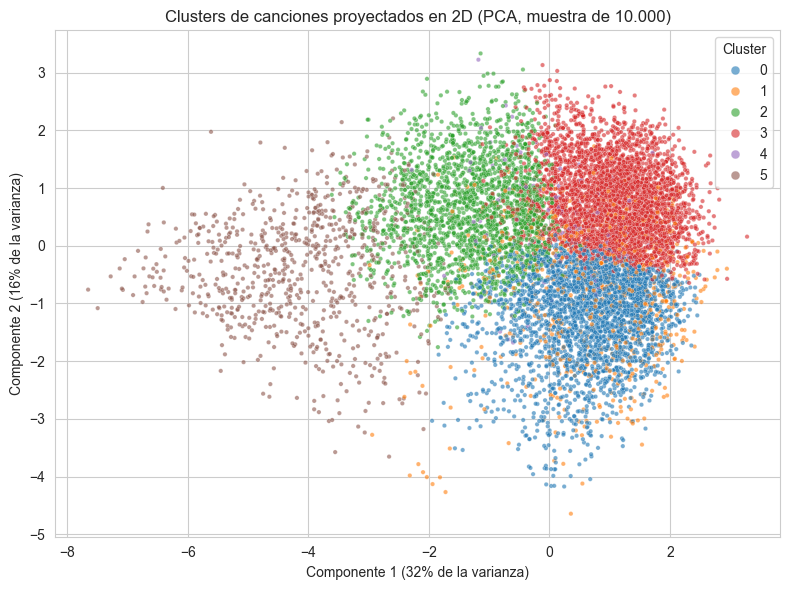

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
vista = rng.choice(len(X), 10000, replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[vista, 0], y=coords[vista, 1], hue=df['cluster'].values[vista],
                palette='tab10', s=10, alpha=0.6)
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)')
plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)')
plt.title('Clusters de canciones proyectados en 2D (PCA, muestra de 10.000)')
plt.legend(title='Cluster', markerscale=2)
plt.tight_layout()
plt.savefig('../images/clustering_pca.png', dpi=100)
plt.show()

Los grupos se ven **continuos y con solapamiento** (consistente con la silueta ≈ 0,19), salvo los clusters más extremos (5 y 4), que se separan mejor.

### 8.8 Robustez y limitaciones del clustering

La silueta global (≈ 0,19) ya indica grupos que se solapan. Antes de usar los segmentos para recomendar acciones al negocio, se revisa **qué tan sólidos son**: tamaño y calidad de cada cluster, efecto de las variables muy asimétricas, estabilidad frente a la semilla y a los datos, y comparación con k = 7.

Ninguna de estas pruebas modifica el modelo final (k = 6, variables estandarizadas): sirven para dimensionar qué conclusiones se pueden sostener y cuáles no.

#### 8.8.1 Tamaño y calidad de cada cluster

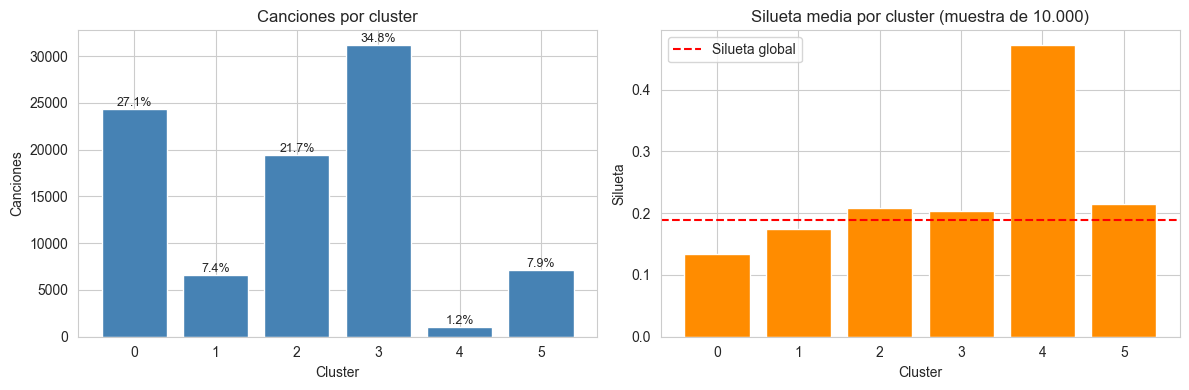

   canciones  % catalogo  puntos en muestra  silueta media
0      24302        27.1               2663          0.133
1       6639         7.4                693          0.174
2      19471        21.7               2163          0.209
3      31186        34.8               3582          0.204
4       1052         1.2                126          0.472
5       7090         7.9                773          0.214

Puntos con silueta negativa (posiblemente mal asignados): 4.8%


In [10]:
from sklearn.metrics import silhouette_samples

etq_muestra = kmeans.labels_[muestra]
sil_i = silhouette_samples(X[muestra], etq_muestra)
sil_cluster = pd.Series(sil_i).groupby(etq_muestra).mean()
tam = df['cluster'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(tam.index.astype(str), tam.values, color='steelblue')
for i, v in enumerate(tam.values):
    axes[0].text(i, v, f'{v / len(df):.1%}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Canciones por cluster'); axes[0].set_xlabel('Cluster'); axes[0].set_ylabel('Canciones')

axes[1].bar(sil_cluster.index.astype(str), sil_cluster.values, color='darkorange')
axes[1].axhline(silhouette_score(X[muestra], kmeans.labels_[muestra]), color='red', linestyle='--', label='Silueta global')
axes[1].set_title('Silueta media por cluster (muestra de 10.000)'); axes[1].set_xlabel('Cluster'); axes[1].set_ylabel('Silueta')
axes[1].legend()
plt.tight_layout()
plt.savefig('../images/clustering_tamano_silueta.png', dpi=100)
plt.show()

print(pd.DataFrame({'canciones': tam, '% catalogo': (tam / len(df) * 100).round(1),
                    'puntos en muestra': pd.Series(etq_muestra).value_counts().sort_index(),
                    'silueta media': sil_cluster.round(3)}).to_string())
print(f'\nPuntos con silueta negativa (posiblemente mal asignados): {(sil_i < 0).mean():.1%}')

**Interpretación:**
- Los clusters 3 (bailables) y 0 (intensas) concentran ≈ 62% de las canciones (34,8% y 27,1%). El cluster 4 (habladas) es pequeño: 1.052 canciones (1,2%).
- La calidad es desigual. El cluster 4 es el mejor separado (silueta 0,47): el contenido hablado es claramente distinto al resto. En cambio, los clusters 0 (0,13) y 1 (0,17) están **bajo la silueta global (0,19)**, es decir, se mezclan más con sus vecinos.
- El 4,8% de las canciones de la muestra tiene silueta negativa: está más cerca de otro cluster que del suyo.
- **Consecuencia:** asignar una canción al cluster 4 o 5 es confiable; asignarla a los clusters 0 y 1 es bastante menos.

#### 8.8.2 Variables muy asimétricas

In [11]:
asim = pd.DataFrame({
    'asimetria (skew)': df[audio_features].skew().round(2),
    '% canciones a más de 3 desv.': (pd.DataFrame(X, columns=audio_features).abs().gt(3).mean() * 100).round(2)
}).sort_values('asimetria (skew)', ascending=False)
asim

,asimetria (skew),% canciones a más de 3 desv.
speechiness,4.55,1.82
liveness,2.06,3.18
instrumentalness,1.56,0.00
acousticness,0.66,0.00
tempo,0.18,0.21
valence,0.13,0.00
danceability,-0.40,0.17
energy,-0.56,0.00
loudness,-1.96,2.19


**Interpretación:** `speechiness` (asimetría 4,55), `liveness` (2,06) e `instrumentalness` (1,56) tienen colas largas hacia valores altos, y `loudness` (−1,96) hacia valores bajos.
- La estandarización (media 0, desviación 1) **solo cambia la escala; no corrige la asimetría**. Por eso unas pocas canciones extremas pesan mucho en las distancias: 1,8% de las canciones está a más de 3 desviaciones en `speechiness`, 3,2% en `liveness` y 2,2% en `loudness`.
- Esto se nota en los resultados: el cluster 4 queda definido por `speechiness` +6,7 desv. y el cluster 1 por `liveness` +2,6 desv. (ver 8.5), es decir, por **valores extremos** de una sola variable.

#### 8.8.3 Sensibilidad a la transformación de las variables

In [12]:
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import adjusted_rand_score

def eta2(etiquetas):
    """Proporción de la variabilidad de popularity explicada por las etiquetas de cluster."""
    media = df['popularity'].mean()
    ss_entre = sum(len(g) * (g.mean() - media) ** 2 for _, g in df.groupby(etiquetas)['popularity'])
    return ss_entre / ((df['popularity'] - media) ** 2).sum()

# Variante 1: log1p sobre las variables acotadas en [0, 1] más asimétricas y luego estandarizar
X_log = df[audio_features].copy()
for col in ['speechiness', 'liveness', 'instrumentalness', 'acousticness']:
    X_log[col] = np.log1p(X_log[col])
X_log = StandardScaler().fit_transform(X_log)
# Variante 2: Yeo-Johnson (aproxima cada variable a una distribución simétrica) y estandariza
X_yj = PowerTransformer(method='yeo-johnson').fit_transform(df[audio_features])

variantes = {'Estandarizada (usada)': X, 'log1p + estandarizada': X_log, 'Yeo-Johnson': X_yj}
filas = []
for nombre, XX in variantes.items():
    fila = {'variante': nombre}
    for k in (5, 6, 7, 8):
        km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(XX)
        fila[f'silueta k={k}'] = round(silhouette_score(XX[muestra], km_k.labels_[muestra]), 3)
        if k == 6:
            etq = km_k.labels_
    fila['ARI vs. original (k=6)'] = round(adjusted_rand_score(kmeans.labels_, etq), 2)
    fila['cluster mas chico'] = int(np.bincount(etq).min())
    fila['cluster mas grande'] = int(np.bincount(etq).max())
    fila['eta² popularity'] = round(eta2(etq), 4)
    filas.append(fila)
pd.DataFrame(filas).set_index('variante').T

variante,Estandarizada (usada),log1p + estandarizada,Yeo-Johnson
silueta k=5,0.177,0.1720,0.1620
silueta k=6,0.188,0.1810,0.1620
silueta k=7,0.195,0.1860,0.1540
silueta k=8,0.177,0.1910,0.1560
ARI vs. original (k=6),1.000,0.6200,0.3900
cluster mas chico,1052.000,4717.0000,8392.0000
cluster mas grande,31186.000,27020.0000,21260.0000
eta² popularity,0.007,0.0172,0.0136


**Interpretación:**
- **Ninguna transformación mejora la silueta.** Con log1p es muy parecida (algo menor en k = 5-7: 0,181 y 0,186 frente a 0,188 y 0,195 para k = 6 y 7; algo mayor en k = 8) y con Yeo-Johnson es claramente menor (0,162 con k = 6). Las siluetas de espacios de variables distintos no son estrictamente comparables, así que se usan solo como referencia.
- **Pero la partición sí cambia:** el ARI (índice de Rand ajustado; 1 = particiones idénticas) respecto de la solución original es 0,62 con log1p y 0,39 con Yeo-Johnson. Con Yeo-Johnson ya no aparece un cluster tan pequeño como el de 1.052 canciones (el menor tiene 8.392), lo que indica que los segmentos "extremos" (habladas, en vivo) dependen de las colas largas de las variables.
- El **eta² de popularity** sube a 1,4-1,7% (frente a 0,7%), pero sigue siendo muy bajo: la conclusión de que el sonido casi no explica la popularidad se mantiene con cualquier variante.
- **Decisión:** se mantiene la versión estandarizada porque no empeora la silueta, los perfiles se leen directamente en las unidades originales y es la base de las cifras del informe. Se declara como limitación que los segmentos extremos son sensibles a esta decisión.

#### 8.8.4 Estabilidad de la solución

In [13]:
etq_ref = kmeans.labels_

# (a) Misma data, 10 semillas distintas (cada una con n_init=10)
filas_sem = []
for s in range(1, 11):
    km_s = KMeans(n_clusters=K, n_init=10, random_state=s).fit(X)
    filas_sem.append({'semilla': s, 'inercia': round(km_s.inertia_, 1),
                      'ARI vs. modelo final': round(adjusted_rand_score(etq_ref, km_s.labels_), 3)})
res_sem = pd.DataFrame(filas_sem)

# (b) Reajustar con una submuestra aleatoria del 80% y asignar todas las canciones
filas_sub = []
for s in range(10):
    idx = np.random.RandomState(200 + s).choice(len(X), int(0.8 * len(X)), replace=False)
    km_s = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X[idx])
    filas_sub.append({'submuestra': s, 'ARI vs. modelo final': round(adjusted_rand_score(etq_ref, km_s.predict(X)), 3)})
res_sub = pd.DataFrame(filas_sub)

print(f'Inercia del modelo final (semilla {RANDOM_STATE}): {kmeans.inertia_:.1f}\n')
print('(a) Semillas distintas:'); print(res_sem.to_string(index=False))
print(f"\n    Semillas con ARI > 0,99: {(res_sem['ARI vs. modelo final'] > 0.99).sum()} de {len(res_sem)}")
print('\n(b) Submuestras del 80%:'); print(res_sub.to_string(index=False))
print(f"\n    Submuestras con ARI > 0,99: {(res_sub['ARI vs. modelo final'] > 0.99).sum()} de {len(res_sub)}")

Inercia del modelo final (semilla 42): 414345.9

(a) Semillas distintas:
 semilla  inercia  ARI vs. modelo final
       1 414977.2                 0.670
       2 414346.4                 0.995
       3 414345.6                 0.998
       4 414345.8                 0.998
       5 414346.4                 0.994
       6 414977.2                 0.670
       7 414345.6                 0.998
       8 414347.5                 0.994
       9 414346.0                 0.999
      10 414345.6                 0.998

    Semillas con ARI > 0,99: 8 de 10

(b) Submuestras del 80%:
 submuestra  ARI vs. modelo final
          0                 0.990
          1                 0.994
          2                 0.996
          3                 0.994
          4                 0.670
          5                 0.993
          6                 0.995
          7                 0.994
          8                 0.993
          9                 0.993

    Submuestras con ARI > 0,99: 8 de 10


**Interpretación:**
- La solución es **estable en la mayoría de los casos**: 8 de 10 semillas y 8 de 10 submuestras del 80% reproducen el modelo final casi idéntico (ARI > 0,99).
- En 2 semillas (1 y 6) y en 1 submuestra (la 4), K-Means cae en **otro óptimo local** (ARI 0,67) con una inercia algo mayor (414.977 frente a ≈ 414.346, un 0,15% peor) y tamaños distintos para varios clusters. El modelo final (inercia 414.345,9) es prácticamente igual a la mejor solución encontrada (414.345,6).
- **Implicancia:** la segmentación es un resumen razonable, no una verdad única. Si se reentrena con otra semilla pueden cambiar los números de cluster y, en algunos casos, los tamaños y porcentajes por segmento. Por eso se fija `random_state = 42` y se guarda el modelo (`kmeans.joblib`).

#### 8.8.5 Comparación k = 6 vs. k = 7

In [14]:
km7 = KMeans(n_clusters=7, n_init=10, random_state=RANDOM_STATE).fit(X)

# Silueta con 5 muestras distintas de 10.000 canciones (para ver cuánto depende de la muestra)
def silueta_muestras(etiquetas):
    vals = [silhouette_score(X[m], etiquetas[m])
            for m in (np.random.RandomState(100 + s).choice(len(X), 10000, replace=False) for s in range(5))]
    return np.mean(vals), np.std(vals)

for nombre, etq in [('k = 6', kmeans.labels_), ('k = 7', km7.labels_)]:
    media_s, sd_s = silueta_muestras(etq)
    print(f'{nombre}: silueta media {media_s:.3f} (desv. {sd_s:.3f} entre 5 muestras) | eta² popularity = {eta2(etq):.1%}')

print('\nCómo se reparten las canciones de cada cluster de k = 6 (filas) en los clusters de k = 7 (columnas):')
print(pd.crosstab(kmeans.labels_, km7.labels_, rownames=['k=6'], colnames=['k=7']).to_string())

base_g = df[genre_cols].mean()
filas7 = []
for c in range(7):
    mask = km7.labels_ == c
    lift = (df.loc[mask, genre_cols].mean() / base_g)[df.loc[mask, genre_cols].mean() > 0.02].sort_values(ascending=False).head(3)
    filas7.append({'cluster k=7': c, 'canciones': int(mask.sum()),
                   'popularity media': round(df.loc[mask, 'popularity'].mean(), 1),
                   '% top (>70)': round((df.loc[mask, 'popularity'] > 70).mean() * 100, 1),
                   'géneros característicos': ', '.join(g.replace('genre_', '') for g in lift.index)})
print('\nSegmentos con k = 7:')
pd.DataFrame(filas7).set_index('cluster k=7')

k = 6: silueta media 0.191 (desv. 0.002 entre 5 muestras) | eta² popularity = 0.7%
k = 7: silueta media 0.197 (desv. 0.002 entre 5 muestras) | eta² popularity = 1.9%

Cómo se reparten las canciones de cada cluster de k = 6 (filas) en los clusters de k = 7 (columnas):
k=7      0      1      2     3     4     5     6
k=6                                             
0       47  17091     71    19     0     0  7074
1        4    261     38  6174     0     0   162
2    17965    313    442     5     0     0   746
3        0   2538  26951     0     0     0  1697
4        0      2      4     0     0  1045     1
5      102      0      0     8  6551     0   429

Segmentos con k = 7:


,canciones,popularity media,% top (>70),géneros característicos
cluster k=7,,,,
0,18118,33.5,2.7,"tango, romance, honky-tonk"
1,20205,35.6,3.5,"metalcore, grunge, heavy-metal"
2,27506,34.4,4.9,"reggaeton, latino, reggae"
3,6206,35.0,1.3,"pagode, sertanejo, samba"
4,6551,28.8,0.4,"new-age, sleep, classical"
5,1045,24.6,0.5,"comedy, show-tunes"
6,10109,27.3,0.5,"minimal-techno, detroit-techno, techno"


**Interpretación:**
- **Silueta:** k = 7 es consistentemente algo mayor (0,197 frente a 0,191 en promedio de 5 muestras; la variación entre muestras es ≈ 0,002), pero la diferencia es pequeña en términos absolutos: ambos indican grupos solapados.
- **Qué cambia:** k = 7 divide el cluster 0 de k = 6 ("intensas") en dos: 17.091 canciones pasan a un cluster de **metal/grunge** y 7.074 a un cluster de **techno** (`minimal-techno`, `detroit-techno`, `techno`). Ese cluster de techno queda con 10.109 canciones porque también recoge algunas de otros clusters. Los demás segmentos se mantienen casi iguales.
- **Relevancia para el negocio:** el segmento de techno tiene popularity media de 27,3 y solo 0,5% de canciones top, frente a 35,6 y 3,5% del segmento de metal. Con k = 6 esa diferencia queda escondida dentro del cluster 0 (33,3 y 2,6%). Coherentemente, el eta² sube de 0,7% a 1,9%.
- **Por qué se mantiene k = 6:** la mejora de silueta es marginal, hay un segmento menos que interpretar y las cifras y recomendaciones del informe están construidas sobre k = 6. Aun así, **k = 7 es una alternativa igualmente defendible** y preferible si el negocio necesita distinguir la música electrónica.

#### 8.8.6 Resumen de limitaciones del clustering

1. **Solapamiento:** silueta global de 0,19 y 4,8% de canciones con silueta negativa; los clusters 0 y 1 son los menos definidos (0,13 y 0,17). Los segmentos son tendencias, no categorías cerradas.
2. **Variables asimétricas sin transformar:** `speechiness` (4,55), `liveness` (2,06), `instrumentalness` (1,56) y `loudness` (−1,96). Los clusters 4 (`speechiness` +6,7 desv.) y 1 (`liveness` +2,6 desv.) están definidos por valores extremos. Al aplicar Yeo-Johnson la partición cambia bastante (ARI 0,39) y la silueta no mejora, así que se mantuvo la estandarización simple.
3. **Silueta calculada sobre una muestra** de 10.000 canciones (por costo computacional). Con 5 muestras distintas varía solo ≈ 0,002, por lo que el valor bajo refleja solapamiento real y no un efecto del muestreo.
4. **Estabilidad:** 8 de 10 semillas y 8 de 10 submuestras reproducen la solución; el resto cae en un óptimo local algo peor (ARI 0,67). Los tamaños por segmento pueden variar si se reentrena con otra semilla.
5. **Elección de k:** k = 7 tiene silueta apenas mayor y separa un segmento de techno menos popular. Se mantuvo k = 6 por simplicidad y consistencia con el resto del informe.
6. **Solo información de audio:** el clustering no incluye artista, fecha de lanzamiento ni marketing, y el cluster explica solo ≈ 0,7% de la variabilidad de `popularity` (1,4-1,9% con las variantes probadas). **Sirve para segmentar el catálogo y diferenciar campañas, no para predecir popularidad.**
7. **Dataset balanceado por construcción:** cada género tiene entre 904 y 1.000 canciones, por lo que el tamaño de los clusters refleja la composición de este dataset y no la del mercado real.

### 8.9 Guardado del modelo y de las asignaciones

In [15]:
joblib.dump(scaler, '../models/scaler_clustering.joblib')
joblib.dump(kmeans, '../models/kmeans.joblib')
df[['track_id', 'cluster']].to_csv('../data/processed/clusters_canciones.csv', index=False)

## 9. Conclusiones y recomendaciones de la etapa no supervisada

1. El catálogo se puede dividir en **6 segmentos de sonido interpretables**, que coinciden con familias de géneros.
2. El sonido **no determina la popularidad** (el cluster explica ≈ 0,7%), pero sí cambia la probabilidad de ser un éxito: el segmento **bailable y alegre** concentra la mayor proporción de canciones top.
3. **Recomendaciones para la distribuidora:**
   - Usar los segmentos para **diferenciar campañas**: no esperar la misma popularidad de una pista ambiental o hablada que de una bailable; fijar metas de reproducciones por segmento.
   - Para el segmento **bailable y alegre** (el de mayor % de top), priorizar la inversión en promoción en playlists masivas.
   - Para los segmentos **de nicho** (ambientales, habladas, en vivo), apuntar a playlists temáticas (sueño, estudio, humor, música regional) en vez de campañas generales.
   - Si el catálogo incluye mucha música electrónica, evaluar la versión con **k = 7**: separa un segmento de techno con menor popularidad (27,3 y 0,5% de top) que con k = 6 queda mezclado con el metal.
   - Combinar este análisis con el modelo supervisado: el cluster y el género permiten **comparar una canción contra su propio segmento**, no contra todo el catálogo.
4. **Limitaciones (detalle en 8.8):**
   - Los clusters se solapan (silueta ≈ 0,19; 4,8% de canciones con silueta negativa), por lo que son **tendencias y no categorías cerradas**.
   - Las variables muy asimétricas (`speechiness`, `liveness`, `instrumentalness`) se estandarizaron sin transformar y los clusters 1 y 4 están definidos por valores extremos; con transformaciones la silueta no mejora, pero la partición cambia.
   - La solución es estable en 8 de 10 semillas; el resto cae en un óptimo local algo peor.
   - Solo se usó información de audio. Se recomienda repetir el análisis si se incorporan artista o fecha de lanzamiento.